In [3]:
# ============================================================
# WHEAT RESTART -- CELL A
# Copy all 3 splits to writable location + validate + fix class names
# ============================================================
import os, shutil, tensorflow as tf
 
SOURCE_BASE = "/kaggle/input/datasets/kushagra3204/wheat-plant-diseases/data"
WORKING_BASE = "/kaggle/working/wheat_clean_full"
 
# Copy all 3 splits
os.makedirs(WORKING_BASE, exist_ok=True)
for split in ["train", "valid", "test"]:
    dst = os.path.join(WORKING_BASE, split)
    if os.path.exists(dst):
        print(f"{split}/ already exists, skipping copy.")
        continue
    print(f"Copying {split}/...")
    shutil.copytree(os.path.join(SOURCE_BASE, split), dst)
    print(f"  Done.")
 
# Validate all 3 splits (remove corrupt images)
def validate(root):
    removed = 0
    for cls in os.listdir(root):
        cls_dir = os.path.join(root, cls)
        if not os.path.isdir(cls_dir): continue
        for f in os.listdir(cls_dir):
            fpath = os.path.join(cls_dir, f)
            try:
                tf.image.decode_image(tf.io.read_file(fpath))
            except:
                os.remove(fpath)
                removed += 1
    return removed
 
print("\n=== Validating ===")
for split in ["train", "valid", "test"]:
    r = validate(os.path.join(WORKING_BASE, split))
    print(f"{split}/: removed {r} corrupt files")
 
# Fix class folder names in valid/ and test/ to match train/
CANONICAL = [
    "Aphid", "Black Rust", "Blast", "Brown Rust", "Common Root Rot",
    "Fusarium Head Blight", "Healthy", "Leaf Blight", "Mildew", "Mite",
    "Septoria", "Smut", "Stem fly", "Tan spot", "Yellow Rust"
]
 
def normalize(name, split):
    n = name.lower()
    for s in [f"_{split}", "_test", "_valid", "_train"]:
        n = n.replace(s, "")
    n = n.strip("_").replace("_","").replace(" ","")
    for c in CANONICAL:
        if c.lower().replace(" ","") == n:
            return c
    return None
 
print("\n=== Fixing class names ===")
for split in ["valid", "test"]:
    split_dir = os.path.join(WORKING_BASE, split)
    for folder in os.listdir(split_dir):
        canon = normalize(folder, split)
        if canon and folder != canon:
            os.rename(os.path.join(split_dir, folder), os.path.join(split_dir, canon))
            print(f"  {split}/: '{folder}' -> '{canon}'")
 
print("Done! All splits ready.")

2026-06-25 05:38:48.839695: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1782365929.304776      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1782365929.460873      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1782365930.718754      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1782365930.718795      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1782365930.718797      58 computation_placer.cc:177] computation placer alr

Copying train/...
  Done.
Copying valid/...
  Done.
Copying test/...
  Done.

=== Validating ===


I0000 00:00:1782366200.042222      58 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1782366200.048241      58 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


train/: removed 35 corrupt files
valid/: removed 1 corrupt files
test/: removed 1 corrupt files

=== Fixing class names ===
  valid/: 'aphid_valid' -> 'Aphid'
  valid/: 'brown_rust_valid' -> 'Brown Rust'
  valid/: 'leaf_blight_valid' -> 'Leaf Blight'
  valid/: 'septoria_valid' -> 'Septoria'
  valid/: 'healthy_valid' -> 'Healthy'
  valid/: 'smut_valid' -> 'Smut'
  valid/: 'mite_valid' -> 'Mite'
  valid/: 'fusarium_head_blight_valid' -> 'Fusarium Head Blight'
  valid/: 'stem_fly_valid' -> 'Stem fly'
  valid/: 'blast_test_valid' -> 'Blast'
  valid/: 'tan_spot_valid' -> 'Tan spot'
  valid/: 'mildew_valid' -> 'Mildew'
  valid/: 'black_rust_valid' -> 'Black Rust'
  valid/: 'common_root_rot_valid' -> 'Common Root Rot'
  valid/: 'yellow_rust_valid' -> 'Yellow Rust'
  test/: 'common_root_rot_test' -> 'Common Root Rot'
  test/: 'yellow_rust_test' -> 'Yellow Rust'
  test/: 'blast_test' -> 'Blast'
  test/: 'stem_fly_test' -> 'Stem fly'
  test/: 'tan_spot_test' -> 'Tan spot'
  test/: 'leaf_blight_t

In [4]:
# WHEAT RESTART -- CELL B
# Merge all 3 splits into one folder for proper 80/20 resplit
# ============================================================
MERGED_DIR = "/kaggle/working/wheat_all"
os.makedirs(MERGED_DIR, exist_ok=True)
 
print("=== Merging train + valid + test ===")
for split in ["train", "valid", "test"]:
    split_dir = os.path.join(WORKING_BASE, split)
    for cls in os.listdir(split_dir):
        cls_src = os.path.join(split_dir, cls)
        cls_dst = os.path.join(MERGED_DIR, cls)
        if not os.path.isdir(cls_src): continue
        os.makedirs(cls_dst, exist_ok=True)
        for fname in os.listdir(cls_src):
            src = os.path.join(cls_src, fname)
            dst = os.path.join(cls_dst, f"{split}_{fname}")
            if not os.path.exists(dst):
                shutil.copy2(src, dst)
 
print("\n=== Final merged counts ===")
total = 0
for cls in sorted(os.listdir(MERGED_DIR)):
    cls_dir = os.path.join(MERGED_DIR, cls)
    n = len([f for f in os.listdir(cls_dir) if f.lower().endswith((".jpg",".jpeg",".png"))])
    print(f"  {cls}: {n}")
    total += n
print(f"\nTOTAL: {total} images across 15 classes")
print(f"DATA_DIR = '{MERGED_DIR}'")

=== Merging train + valid + test ===

=== Final merged counts ===
  Aphid: 968
  Black Rust: 646
  Blast: 715
  Brown Rust: 1341
  Common Root Rot: 684
  Fusarium Head Blight: 681
  Healthy: 1070
  Leaf Blight: 912
  Mildew: 1121
  Mite: 870
  Septoria: 1214
  Smut: 1380
  Stem fly: 304
  Tan spot: 840
  Yellow Rust: 1371

TOTAL: 14117 images across 15 classes
DATA_DIR = '/kaggle/working/wheat_all'


In [5]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications.efficientnet import EfficientNetB0, preprocess_input
from tensorflow.keras.applications import EfficientNetV2S
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input
import numpy as np
import json
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
 
DATA_DIR = "/kaggle/working/wheat_all"
IMG_SIZE = (384, 384)
BATCH_SIZE = 32
SEED = 42

In [6]:
import os, shutil, tensorflow as tf

In [7]:
# Load with proper 80/20 split on ALL 14,117 images
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", validation_split=0.2,
    subset="training", seed=SEED
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", validation_split=0.2,
    subset="validation", seed=SEED
)
 
class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Classes:", class_names)
print("Number of classes:", NUM_CLASSES)
 
with open("/kaggle/working/wheat_class_names.json", "w") as f:
    json.dump(class_names, f, indent=2)

Found 14117 files belonging to 15 classes.
Using 11294 files for training.
Found 14117 files belonging to 15 classes.
Using 2823 files for validation.
Classes: ['Aphid', 'Black Rust', 'Blast', 'Brown Rust', 'Common Root Rot', 'Fusarium Head Blight', 'Healthy', 'Leaf Blight', 'Mildew', 'Mite', 'Septoria', 'Smut', 'Stem fly', 'Tan spot', 'Yellow Rust']
Number of classes: 15


In [8]:
# Class weights
labels_flat = []
for i, cls in enumerate(class_names):
    n = len([f for f in os.listdir(os.path.join(DATA_DIR, cls))
             if f.lower().endswith((".jpg",".jpeg",".png"))])
    labels_flat.extend([i] * n)
labels_flat = np.array(labels_flat)
cw_values = compute_class_weight("balanced", classes=np.unique(labels_flat), y=labels_flat)
class_weight_dict = {i: w for i, w in enumerate(cw_values)}
print("\nClass weights:")
for i, cls in enumerate(class_names):
    print(f"  {cls}: {class_weight_dict[i]:.3f}")


Class weights:
  Aphid: 0.972
  Black Rust: 1.457
  Blast: 1.316
  Brown Rust: 0.702
  Common Root Rot: 1.376
  Fusarium Head Blight: 1.382
  Healthy: 0.880
  Leaf Blight: 1.032
  Mildew: 0.840
  Mite: 1.082
  Septoria: 0.775
  Smut: 0.682
  Stem fly: 3.096
  Tan spot: 1.120
  Yellow Rust: 0.686


In [9]:
# Augmentation + preprocessing
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.3),
    layers.RandomZoom(0.2),
    layers.RandomBrightness(0.2),
    layers.RandomContrast(0.2),
])
 
def prep_train(img, lbl):
    return preprocess_input(augmentation(img)), lbl
def prep_val(img, lbl):
    return preprocess_input(img), lbl
 
train_ds_p = train_ds.map(prep_train, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
val_ds_p   = val_ds.map(prep_val,   num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
 

In [ ]:
# Build model
base = EfficientNetV2S(include_top=False, weights="imagenet", input_shape=(384,384,3))
base.trainable = False
inputs  = keras.Input(shape=(384,384,3))
x = base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)
 
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint("/kaggle/working/wheat_best.keras", monitor="val_accuracy", save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6)
]

In [ ]:
# PHASE 1
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="categorical_crossentropy", metrics=["accuracy"])
print("\n=== PHASE 1: Frozen base (lr=1e-3) ===")
h1 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=5,
               class_weight=class_weight_dict, callbacks=callbacks)

In [ ]:
# PHASE 2
base.trainable = True
model.compile(optimizer=keras.optimizers.Adam(1e-4),
              loss="categorical_crossentropy", metrics=["accuracy"])
print("\n=== PHASE 2: Full fine-tune (lr=1e-4) ===")
h2 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=10,
               class_weight=class_weight_dict, callbacks=callbacks)

In [ ]:
import tensorflow as tf, os, json
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetV2S
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input
import numpy as np

base = EfficientNetV2S(include_top=False, weights="imagenet", input_shape=(384,384,3))
base.trainable = True

inputs  = keras.Input(shape=(384,384,3))
x = base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(15, activation="softmax")(x)
model = keras.Model(inputs, outputs)

model.load_weights("/kaggle/working/wheat_best.keras")
print("✅ Weights loaded — ready for Phase 3!")

In [ ]:
# Class weights
labels_flat = []
for i, cls in enumerate(class_names):
    n = len([f for f in os.listdir(os.path.join(DATA_DIR, cls))
             if f.lower().endswith((".jpg",".jpeg",".png"))])
    labels_flat.extend([i] * n)
labels_flat = np.array(labels_flat)
from sklearn.utils.class_weight import compute_class_weight
cw_values = compute_class_weight("balanced", classes=np.unique(labels_flat), y=labels_flat)
class_weight_dict = {i: w for i, w in enumerate(cw_values)}
print("✅ Data ready!")

In [ ]:
# PHASE 3
model.compile(optimizer=keras.optimizers.Adam(3e-5),
              loss="categorical_crossentropy", metrics=["accuracy"])
print("\n=== PHASE 3: Extended fine-tune (lr=3e-5) ===")
h3 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=15,
               class_weight=class_weight_dict, callbacks=callbacks)

In [ ]:
# Run this after epoch 2 finishes - unfreeze ALL layers
for layer in base.layers:
    layer.trainable = True

model.compile(optimizer=keras.optimizers.Adam(1e-5),  # very low LR to avoid destroying weights
              loss="categorical_crossentropy", metrics=["accuracy"])

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint("/kaggle/working/wheat_best.keras", monitor="val_accuracy", save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7)
]

print("=== PHASE 3B: Full unfreeze (lr=1e-5) ===")
h3b = model.fit(train_ds_p, validation_data=val_ds_p, epochs=8,
                class_weight=class_weight_dict, callbacks=callbacks)

model.save("/kaggle/working/wheat_final.keras")
print(f"🎯 Best: {max(h3b.history['val_accuracy'])*100:.2f}%")

In [ ]:
# Save model
model.save("/kaggle/working/wheat_final.keras")
print(f"\nModel saved. Size: {os.path.getsize('/kaggle/working/wheat_final.keras')/1024/1024:.1f} MB")

In [ ]:
# Evaluation
y_true, y_pred = [], []
for imgs, lbls in val_ds_p:
    preds = model.predict(imgs, verbose=0)
    y_true.extend(np.argmax(lbls.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))
 
print("\n=== Classification Report ===")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
 
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(14, 11))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title("Wheat Disease Classification -- Confusion Matrix")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
plt.savefig("/kaggle/working/wheat_confusion_matrix.png", dpi=150)
plt.show()
print(f"\nFinal val accuracy: {max(h3.history['val_accuracy'])*100:.2f}%")

In [ ]:
# WHEAT RESTART -- CELL D (Final package)
# Generate class_map.json and zip everything
# ============================================================
import zipfile
 
DISEASE_NAMES = {
    "Aphid": "Aphid", "Black Rust": "Black Rust", "Blast": "Blast",
    "Brown Rust": "Brown Rust", "Common Root Rot": "Common Root Rot",
    "Fusarium Head Blight": "Fusarium Head Blight", "Healthy": "Healthy",
    "Leaf Blight": "Leaf Blight", "Mildew": "Mildew", "Mite": "Mite",
    "Septoria": "Septoria", "Smut": "Smut", "Stem fly": "Stem Fly",
    "Tan spot": "Tan Spot", "Yellow Rust": "Yellow Rust"
}
 
wheat_class_map = {}
production_class_names = []
for cls in class_names:
    key = "wheat__" + cls.lower().replace(" ", "_")
    production_class_names.append(key)
    wheat_class_map[key] = {"crop": "Wheat", "disease": DISEASE_NAMES.get(cls, cls)}
 
with open("/kaggle/working/wheat_class_map.json", "w") as f:
    json.dump(wheat_class_map, f, indent=2)
with open("/kaggle/working/wheat_class_names.json", "w") as f:
    json.dump(production_class_names, f, indent=2)
 
print("=== wheat_class_map.json ===")
print(json.dumps(wheat_class_map, indent=2))
 
files = [
    "/kaggle/working/wheat_final.keras",
    "/kaggle/working/wheat_best.keras",
    "/kaggle/working/wheat_class_map.json",
    "/kaggle/working/wheat_class_names.json",
    "/kaggle/working/wheat_confusion_matrix.png",
]
 
print("\n=== Output files ===")
for f in files:
    if os.path.exists(f):
        print(f"  [OK] {f} ({os.path.getsize(f)/1024:.0f} KB)")
    else:
        print(f"  [MISSING] {f}")
 
zip_path = "/kaggle/working/wheat_model_package.zip"
with zipfile.ZipFile(zip_path, "w") as zf:
    for f in files:
        if os.path.exists(f):
            zf.write(f, arcname=os.path.basename(f))
print(f"\nZip: {zip_path} ({os.path.getsize(zip_path)/1024/1024:.1f} MB)")
print("\nDo Save Version -> Save & Run All (Commit) now!")

In [1]:
import os, shutil, tensorflow as tf

SOURCE_BASE = "/kaggle/input/datasets/kushagra3204/wheat-plant-diseases/data"
WORKING_BASE = "/kaggle/working/wheat_clean_full"

os.makedirs(WORKING_BASE, exist_ok=True)
for split in ["train", "valid", "test"]:
    dst = os.path.join(WORKING_BASE, split)
    if os.path.exists(dst):
        print(f"{split}/ already exists, skipping copy.")
        continue
    print(f"Copying {split}/...")
    shutil.copytree(os.path.join(SOURCE_BASE, split), dst)
    print(f"  Done.")

def validate(root):
    removed = 0
    for cls in os.listdir(root):
        cls_dir = os.path.join(root, cls)
        if not os.path.isdir(cls_dir): continue
        for f in os.listdir(cls_dir):
            fpath = os.path.join(cls_dir, f)
            try:
                tf.image.decode_image(tf.io.read_file(fpath))
            except:
                os.remove(fpath)
                removed += 1
    return removed

print("\n=== Validating ===")
for split in ["train", "valid", "test"]:
    r = validate(os.path.join(WORKING_BASE, split))
    print(f"{split}/: removed {r} corrupt files")

CANONICAL = [
    "Aphid", "Black Rust", "Blast", "Brown Rust", "Common Root Rot",
    "Fusarium Head Blight", "Healthy", "Leaf Blight", "Mildew", "Mite",
    "Septoria", "Smut", "Stem fly", "Tan spot", "Yellow Rust"
]

def normalize(name, split):
    n = name.lower()
    for s in [f"_{split}", "_test", "_valid", "_train"]:
        n = n.replace(s, "")
    n = n.strip("_").replace("_","").replace(" ","")
    for c in CANONICAL:
        if c.lower().replace(" ","") == n:
            return c
    return None

print("\n=== Fixing class names ===")
for split in ["valid", "test"]:
    split_dir = os.path.join(WORKING_BASE, split)
    for folder in os.listdir(split_dir):
        canon = normalize(folder, split)
        if canon and folder != canon:
            os.rename(os.path.join(split_dir, folder), os.path.join(split_dir, canon))
            print(f"  {split}/: '{folder}' -> '{canon}'")

print("Done! All splits ready.")

2026-06-25 05:49:50.038485: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1782366590.243457      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1782366590.304532      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1782366590.805809      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1782366590.805878      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1782366590.805883      58 computation_placer.cc:177] computation placer alr

Copying train/...
  Done.
Copying valid/...
  Done.
Copying test/...
  Done.

=== Validating ===


I0000 00:00:1782366794.717990      58 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1782366794.724426      58 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


train/: removed 35 corrupt files
valid/: removed 1 corrupt files
test/: removed 1 corrupt files

=== Fixing class names ===
  valid/: 'mite_valid' -> 'Mite'
  valid/: 'healthy_valid' -> 'Healthy'
  valid/: 'blast_test_valid' -> 'Blast'
  valid/: 'black_rust_valid' -> 'Black Rust'
  valid/: 'mildew_valid' -> 'Mildew'
  valid/: 'yellow_rust_valid' -> 'Yellow Rust'
  valid/: 'fusarium_head_blight_valid' -> 'Fusarium Head Blight'
  valid/: 'aphid_valid' -> 'Aphid'
  valid/: 'septoria_valid' -> 'Septoria'
  valid/: 'stem_fly_valid' -> 'Stem fly'
  valid/: 'leaf_blight_valid' -> 'Leaf Blight'
  valid/: 'smut_valid' -> 'Smut'
  valid/: 'tan_spot_valid' -> 'Tan spot'
  valid/: 'common_root_rot_valid' -> 'Common Root Rot'
  valid/: 'brown_rust_valid' -> 'Brown Rust'
  test/: 'healthy_test' -> 'Healthy'
  test/: 'yellow_rust_test' -> 'Yellow Rust'
  test/: 'common_root_rot_test' -> 'Common Root Rot'
  test/: 'smut_test' -> 'Smut'
  test/: 'mildew_test' -> 'Mildew'
  test/: 'aphid_test' -> 'Aphid

In [2]:
import os, shutil

WORKING_BASE = "/kaggle/working/wheat_clean_full"
MERGED_DIR = "/kaggle/working/wheat_all"
os.makedirs(MERGED_DIR, exist_ok=True)

print("=== Merging train + valid + test ===")
for split in ["train", "valid", "test"]:
    split_dir = os.path.join(WORKING_BASE, split)
    for cls in os.listdir(split_dir):
        cls_src = os.path.join(split_dir, cls)
        cls_dst = os.path.join(MERGED_DIR, cls)
        if not os.path.isdir(cls_src): continue
        os.makedirs(cls_dst, exist_ok=True)
        for fname in os.listdir(cls_src):
            src = os.path.join(cls_src, fname)
            dst = os.path.join(cls_dst, f"{split}_{fname}")
            if not os.path.exists(dst):
                shutil.copy2(src, dst)

print("\n=== Final merged counts ===")
total = 0
for cls in sorted(os.listdir(MERGED_DIR)):
    cls_dir = os.path.join(MERGED_DIR, cls)
    n = len([f for f in os.listdir(cls_dir) if f.lower().endswith((".jpg",".jpeg",".png"))])
    print(f"  {cls}: {n}")
    total += n
print(f"\nTOTAL: {total} images across 15 classes")

=== Merging train + valid + test ===

=== Final merged counts ===
  Aphid: 968
  Black Rust: 646
  Blast: 715
  Brown Rust: 1341
  Common Root Rot: 684
  Fusarium Head Blight: 681
  Healthy: 1070
  Leaf Blight: 912
  Mildew: 1121
  Mite: 870
  Septoria: 1214
  Smut: 1380
  Stem fly: 304
  Tan spot: 840
  Yellow Rust: 1371

TOTAL: 14117 images across 15 classes


In [3]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetV2S
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input
import numpy as np, os, json
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = "/kaggle/working/wheat_all"
IMG_SIZE = (384, 384)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", validation_split=0.2,
    subset="training", seed=SEED
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
    label_mode="categorical", validation_split=0.2,
    subset="validation", seed=SEED
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Classes:", class_names)

with open("/kaggle/working/wheat_class_names.json", "w") as f:
    json.dump(class_names, f, indent=2)

# Class weights
labels_flat = []
for i, cls in enumerate(class_names):
    n = len([f for f in os.listdir(os.path.join(DATA_DIR, cls))
             if f.lower().endswith((".jpg",".jpeg",".png"))])
    labels_flat.extend([i] * n)
labels_flat = np.array(labels_flat)
cw_values = compute_class_weight("balanced", classes=np.unique(labels_flat), y=labels_flat)
class_weight_dict = {i: w for i, w in enumerate(cw_values)}
print("\nClass weights:")
for i, cls in enumerate(class_names):
    print(f"  {cls}: {class_weight_dict[i]:.3f}")

# Augmentation
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.3),
    layers.RandomZoom(0.2),
    layers.RandomBrightness(0.2),
    layers.RandomContrast(0.2),
])

def prep_train(img, lbl): return preprocess_input(augmentation(img)), lbl
def prep_val(img, lbl):   return preprocess_input(img), lbl

train_ds_p = train_ds.map(prep_train, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)
val_ds_p   = val_ds.map(prep_val,   num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

# Build model
base = EfficientNetV2S(include_top=False, weights="imagenet", input_shape=(384,384,3))
base.trainable = False

inputs  = keras.Input(shape=(384,384,3))
x = base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint("/kaggle/working/wheat_best.keras", monitor="val_accuracy", save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7),
    keras.callbacks.BackupAndRestore("/kaggle/working/backup/")  # auto-recovery if crash
]

Found 14117 files belonging to 15 classes.
Using 11294 files for training.
Found 14117 files belonging to 15 classes.
Using 2823 files for validation.
Classes: ['Aphid', 'Black Rust', 'Blast', 'Brown Rust', 'Common Root Rot', 'Fusarium Head Blight', 'Healthy', 'Leaf Blight', 'Mildew', 'Mite', 'Septoria', 'Smut', 'Stem fly', 'Tan spot', 'Yellow Rust']

Class weights:
  Aphid: 0.972
  Black Rust: 1.457
  Blast: 1.316
  Brown Rust: 0.702
  Common Root Rot: 1.376
  Fusarium Head Blight: 1.382
  Healthy: 0.880
  Leaf Blight: 1.032
  Mildew: 0.840
  Mite: 1.082
  Septoria: 0.775
  Smut: 0.682
  Stem fly: 3.096
  Tan spot: 1.120
  Yellow Rust: 0.686
82420632/82420632 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [4]:
# PHASE 1 — frozen base
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="categorical_crossentropy", metrics=["accuracy"])
print("\n=== PHASE 1: Frozen base (lr=1e-3) ===")
h1 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=10,
               class_weight=class_weight_dict, callbacks=callbacks)
print(f"Phase 1 best: {max(h1.history['val_accuracy'])*100:.2f}%")


=== PHASE 1: Frozen base (lr=1e-3) ===
Epoch 1/10


I0000 00:00:1782367012.848736     129 service.cc:152] XLA service 0x7f1358006420 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1782367012.848784     129 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1782367012.848789     129 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1782367021.280589     129 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-06-25 05:57:13.613557: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 05:57:13.784050: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 05:57:14.927623: E external/local_xl

352/353 ━━━━━━━━━━━━━━━━━━━━ 0s 650ms/step - accuracy: 0.4169 - loss: 2.1382

2026-06-25 06:01:39.844262: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 06:01:40.014944: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 06:01:41.187396: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 06:01:41.370435: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 06:01:43.110498: E external/local_xla/xla/stream_

353/353 ━━━━━━━━━━━━━━━━━━━━ 0s 753ms/step - accuracy: 0.4173 - loss: 2.1368

2026-06-25 06:02:43.965211: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 06:02:44.103935: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 06:02:44.928090: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 06:02:45.069716: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 06:02:46.564381: E external/local_xla/xla/stream_

353/353 ━━━━━━━━━━━━━━━━━━━━ 388s 909ms/step - accuracy: 0.5339 - loss: 1.6420 - val_accuracy: 0.6943 - val_loss: 0.9507 - learning_rate: 0.0010
Epoch 2/10
353/353 ━━━━━━━━━━━━━━━━━━━━ 261s 733ms/step - accuracy: 0.6601 - loss: 1.1406 - val_accuracy: 0.7152 - val_loss: 0.8653 - learning_rate: 0.0010
Epoch 3/10
353/353 ━━━━━━━━━━━━━━━━━━━━ 260s 732ms/step - accuracy: 0.6738 - loss: 1.0626 - val_accuracy: 0.7375 - val_loss: 0.8309 - learning_rate: 0.0010
Epoch 4/10
353/353 ━━━━━━━━━━━━━━━━━━━━ 259s 729ms/step - accuracy: 0.6872 - loss: 1.0109 - val_accuracy: 0.7393 - val_loss: 0.8080 - learning_rate: 0.0010
Epoch 5/10
353/353 ━━━━━━━━━━━━━━━━━━━━ 261s 734ms/step - accuracy: 0.6927 - loss: 0.9916 - val_accuracy: 0.7538 - val_loss: 0.7711 - learning_rate: 0.0010
Epoch 6/10
353/353 ━━━━━━━━━━━━━━━━━━━━ 260s 730ms/step - accuracy: 0.6986 - loss: 0.9947 - val_accuracy: 0.7648 - val_loss: 0.7563 - learning_rate: 0.0010
Epoch 7/10
353/353 ━━━━━━━━━━━━━━━━━━━━ 260s 732ms/step - accuracy: 0.6929 

In [5]:
# PHASE 2 — full unfreeze at 1e-4
base.trainable = True
model.compile(optimizer=keras.optimizers.Adam(1e-4),
              loss="categorical_crossentropy", metrics=["accuracy"])
print("\n=== PHASE 2: Full fine-tune (lr=1e-4) ===")
h2 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=10,
               class_weight=class_weight_dict, callbacks=callbacks)
print(f"Phase 2 best: {max(h2.history['val_accuracy'])*100:.2f}%")


=== PHASE 2: Full fine-tune (lr=1e-4) ===
Epoch 1/10


2026-06-25 06:40:04.820351: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 06:40:05.010293: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 06:40:10.420469: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 06:40:10.600495: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 06:40:12.754941: E external/local_xla/xla/stream_

352/353 ━━━━━━━━━━━━━━━━━━━━ 0s 916ms/step - accuracy: 0.6429 - loss: 1.2583

2026-06-25 06:47:03.137646: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 06:47:03.322715: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 06:47:07.715302: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 06:47:07.893217: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-06-25 06:47:09.754832: E external/local_xla/xla/stream_

353/353 ━━━━━━━━━━━━━━━━━━━━ 649s 1s/step - accuracy: 0.7082 - loss: 1.0089 - val_accuracy: 0.8062 - val_loss: 0.5869 - learning_rate: 1.0000e-04
Epoch 2/10
353/353 ━━━━━━━━━━━━━━━━━━━━ 352s 991ms/step - accuracy: 0.8085 - loss: 0.5893 - val_accuracy: 0.8363 - val_loss: 0.4864 - learning_rate: 1.0000e-04
Epoch 3/10
353/353 ━━━━━━━━━━━━━━━━━━━━ 352s 991ms/step - accuracy: 0.8482 - loss: 0.4584 - val_accuracy: 0.8643 - val_loss: 0.4216 - learning_rate: 1.0000e-04
Epoch 4/10
353/353 ━━━━━━━━━━━━━━━━━━━━ 353s 993ms/step - accuracy: 0.8775 - loss: 0.3625 - val_accuracy: 0.8693 - val_loss: 0.3970 - learning_rate: 1.0000e-04
Epoch 5/10
353/353 ━━━━━━━━━━━━━━━━━━━━ 353s 992ms/step - accuracy: 0.8944 - loss: 0.3067 - val_accuracy: 0.8803 - val_loss: 0.3807 - learning_rate: 1.0000e-04
Epoch 6/10
353/353 ━━━━━━━━━━━━━━━━━━━━ 351s 985ms/step - accuracy: 0.9089 - loss: 0.2630 - val_accuracy: 0.8764 - val_loss: 0.3873 - learning_rate: 1.0000e-04
Epoch 7/10
353/353 ━━━━━━━━━━━━━━━━━━━━ 526s 1s/step -

In [6]:
# PHASE 3 — full unfreeze at 5e-5
model.compile(optimizer=keras.optimizers.Adam(5e-5),
              loss="categorical_crossentropy", metrics=["accuracy"])
print("\n=== PHASE 3: Full fine-tune (lr=5e-5) ===")
h3 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=15,
               class_weight=class_weight_dict, callbacks=callbacks)
print(f"Phase 3 best: {max(h3.history['val_accuracy'])*100:.2f}%")


=== PHASE 3: Full fine-tune (lr=5e-5) ===
Epoch 1/15
353/353 ━━━━━━━━━━━━━━━━━━━━ 617s 1s/step - accuracy: 0.9471 - loss: 0.1353 - val_accuracy: 0.8905 - val_loss: 0.3880 - learning_rate: 5.0000e-05
Epoch 2/15
353/353 ━━━━━━━━━━━━━━━━━━━━ 353s 995ms/step - accuracy: 0.9512 - loss: 0.1244 - val_accuracy: 0.8998 - val_loss: 0.3706 - learning_rate: 5.0000e-05
Epoch 3/15
353/353 ━━━━━━━━━━━━━━━━━━━━ 350s 983ms/step - accuracy: 0.9565 - loss: 0.1134 - val_accuracy: 0.8976 - val_loss: 0.3751 - learning_rate: 5.0000e-05
Epoch 4/15
353/353 ━━━━━━━━━━━━━━━━━━━━ 535s 2s/step - accuracy: 0.9587 - loss: 0.1063 - val_accuracy: 0.8980 - val_loss: 0.3807 - learning_rate: 5.0000e-05
Epoch 5/15
353/353 ━━━━━━━━━━━━━━━━━━━━ 351s 987ms/step - accuracy: 0.9610 - loss: 0.0909 - val_accuracy: 0.8937 - val_loss: 0.3754 - learning_rate: 1.5000e-05
Phase 3 best: 89.98%


In [7]:
# Load best weights first
model.load_weights("/kaggle/working/wheat_best.keras")

# PHASE 4 — very low LR to squeeze past 90%
model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="categorical_crossentropy", metrics=["accuracy"])

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint("/kaggle/working/wheat_best.keras", monitor="val_accuracy", save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=3, min_lr=1e-8),
    keras.callbacks.BackupAndRestore("/kaggle/working/backup/")
]

print("=== PHASE 4: Polish (lr=1e-5, patience=5) ===")
h4 = model.fit(train_ds_p, validation_data=val_ds_p, epochs=15,
               class_weight=class_weight_dict, callbacks=callbacks)

model.save("/kaggle/working/wheat_final.keras")
print(f"🎯 Phase 4 best: {max(h4.history['val_accuracy'])*100:.2f}%")

=== PHASE 4: Polish (lr=1e-5, patience=5) ===
Epoch 1/15
353/353 ━━━━━━━━━━━━━━━━━━━━ 623s 1s/step - accuracy: 0.9556 - loss: 0.1097 - val_accuracy: 0.8994 - val_loss: 0.3580 - learning_rate: 1.0000e-05
Epoch 2/15
353/353 ━━━━━━━━━━━━━━━━━━━━ 350s 987ms/step - accuracy: 0.9616 - loss: 0.0906 - val_accuracy: 0.8987 - val_loss: 0.3714 - learning_rate: 1.0000e-05
Epoch 3/15
353/353 ━━━━━━━━━━━━━━━━━━━━ 536s 2s/step - accuracy: 0.9641 - loss: 0.0857 - val_accuracy: 0.9008 - val_loss: 0.3663 - learning_rate: 1.0000e-05
Epoch 4/15
353/353 ━━━━━━━━━━━━━━━━━━━━ 351s 988ms/step - accuracy: 0.9647 - loss: 0.0858 - val_accuracy: 0.8990 - val_loss: 0.3615 - learning_rate: 1.0000e-05
Epoch 5/15
353/353 ━━━━━━━━━━━━━━━━━━━━ 528s 1s/step - accuracy: 0.9633 - loss: 0.0824 - val_accuracy: 0.9012 - val_loss: 0.3618 - learning_rate: 3.0000e-06
Epoch 6/15
353/353 ━━━━━━━━━━━━━━━━━━━━ 354s 995ms/step - accuracy: 0.9642 - loss: 0.0818 - val_accuracy: 0.9044 - val_loss: 0.3641 - learning_rate: 3.0000e-06
Epo

In [8]:
# Save
model.save("/kaggle/working/wheat_final.keras")
print(f"\n✅ Model saved!")
print(f"🎯 Overall best val accuracy: {max(h4.history['val_accuracy'])*100:.2f}%")


✅ Model saved!
🎯 Overall best val accuracy: 90.44%



=== Classification Report ===
                      precision    recall  f1-score   support

               Aphid     0.9653    0.8789    0.9201       190
          Black Rust     0.7464    0.8583    0.7984       120
               Blast     0.9385    0.8905    0.9139       137
          Brown Rust     0.8939    0.8806    0.8872       268
     Common Root Rot     0.8222    0.8880    0.8538       125
Fusarium Head Blight     0.9496    0.9851    0.9670       134
             Healthy     0.9816    0.9907    0.9861       215
         Leaf Blight     0.7356    0.6845    0.7091       187
              Mildew     0.9544    0.9705    0.9623       237
                Mite     0.8834    0.8727    0.8780       165
            Septoria     0.9593    0.9099    0.9339       233
                Smut     0.9673    0.9769    0.9721       303
            Stem fly     0.9394    0.9841    0.9612        63
            Tan spot     0.6704    0.7453    0.7059       161
         Yellow Rust     1.0000    0.9

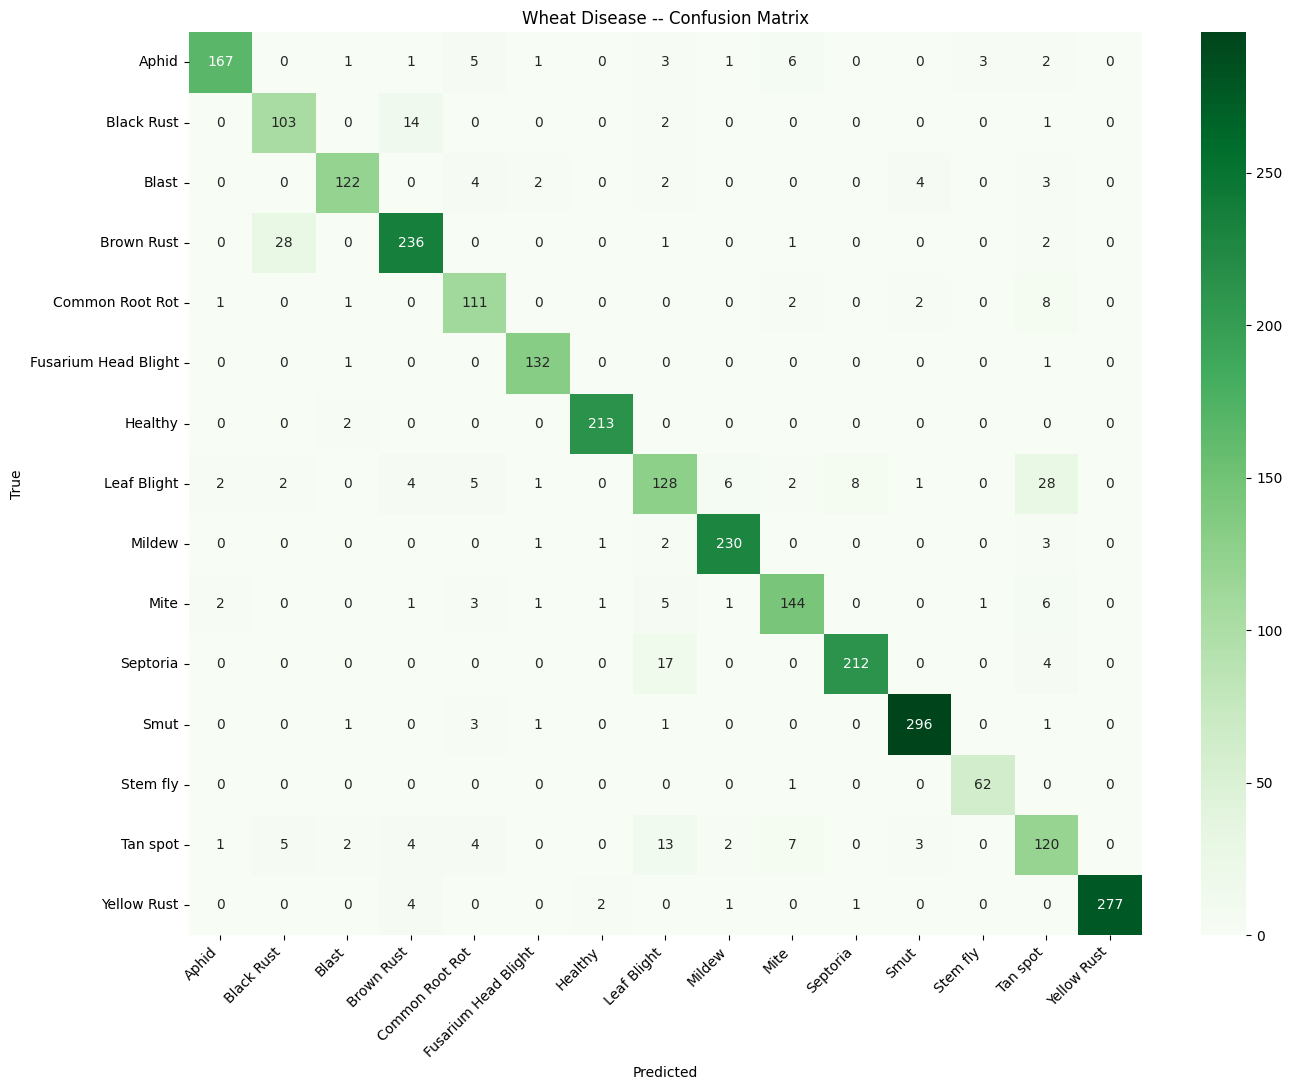

In [9]:
# Evaluation
y_true, y_pred = [], []
for imgs, lbls in val_ds_p:
    preds = model.predict(imgs, verbose=0)
    y_true.extend(np.argmax(lbls.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

print("\n=== Classification Report ===")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(14, 11))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title("Wheat Disease -- Confusion Matrix")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
plt.savefig("/kaggle/working/wheat_confusion_matrix.png", dpi=150)
plt.show()

In [10]:
import zipfile, json, os

class_names = json.load(open("/kaggle/working/wheat_class_names.json"))

DISEASE_NAMES = {
    "Aphid": "Aphid", "Black Rust": "Black Rust", "Blast": "Blast",
    "Brown Rust": "Brown Rust", "Common Root Rot": "Common Root Rot",
    "Fusarium Head Blight": "Fusarium Head Blight", "Healthy": "Healthy",
    "Leaf Blight": "Leaf Blight", "Mildew": "Mildew", "Mite": "Mite",
    "Septoria": "Septoria", "Smut": "Smut", "Stem fly": "Stem Fly",
    "Tan spot": "Tan Spot", "Yellow Rust": "Yellow Rust"
}

wheat_class_map = {}
production_class_names = []
for cls in class_names:
    key = "wheat__" + cls.lower().replace(" ", "_")
    production_class_names.append(key)
    wheat_class_map[key] = {"crop": "Wheat", "disease": DISEASE_NAMES.get(cls, cls)}

with open("/kaggle/working/wheat_class_map.json", "w") as f:
    json.dump(wheat_class_map, f, indent=2)
with open("/kaggle/working/wheat_class_names.json", "w") as f:
    json.dump(production_class_names, f, indent=2)

print("=== wheat_class_map.json ===")
print(json.dumps(wheat_class_map, indent=2))

files = [
    "/kaggle/working/wheat_final.keras",
    "/kaggle/working/wheat_best.keras",
    "/kaggle/working/wheat_class_map.json",
    "/kaggle/working/wheat_class_names.json",
    "/kaggle/working/wheat_confusion_matrix.png",
]

print("\n=== Output files ===")
for f in files:
    if os.path.exists(f):
        print(f"  ✅ {os.path.basename(f)} ({os.path.getsize(f)/1024/1024:.1f} MB)")
    else:
        print(f"  ❌ MISSING: {f}")

zip_path = "/kaggle/working/wheat_model_package.zip"
with zipfile.ZipFile(zip_path, "w") as zf:
    for f in files:
        if os.path.exists(f):
            zf.write(f, arcname=os.path.basename(f))
print(f"\n✅ Zip: {zip_path} ({os.path.getsize(zip_path)/1024/1024:.1f} MB)")

=== wheat_class_map.json ===
{
  "wheat__aphid": {
    "crop": "Wheat",
    "disease": "Aphid"
  },
  "wheat__black_rust": {
    "crop": "Wheat",
    "disease": "Black Rust"
  },
  "wheat__blast": {
    "crop": "Wheat",
    "disease": "Blast"
  },
  "wheat__brown_rust": {
    "crop": "Wheat",
    "disease": "Brown Rust"
  },
  "wheat__common_root_rot": {
    "crop": "Wheat",
    "disease": "Common Root Rot"
  },
  "wheat__fusarium_head_blight": {
    "crop": "Wheat",
    "disease": "Fusarium Head Blight"
  },
  "wheat__healthy": {
    "crop": "Wheat",
    "disease": "Healthy"
  },
  "wheat__leaf_blight": {
    "crop": "Wheat",
    "disease": "Leaf Blight"
  },
  "wheat__mildew": {
    "crop": "Wheat",
    "disease": "Mildew"
  },
  "wheat__mite": {
    "crop": "Wheat",
    "disease": "Mite"
  },
  "wheat__septoria": {
    "crop": "Wheat",
    "disease": "Septoria"
  },
  "wheat__smut": {
    "crop": "Wheat",
    "disease": "Smut"
  },
  "wheat__stem_fly": {
    "crop": "Wheat",
    "di